


# Testing robustness to input noise (`p_flip`)

The model trained (notebook 11) on patterns with `p_flip = 0.01` is evaluated as the
stochasticity of the **trigger** grows: each call of the pattern generator balanced-flips
a fraction `p_flip` of the frozen target's bits, so the input trigger deviates more and
more from the stored memory while keeping its firing rate. A healthy HD-SNN should
degrade gracefully - retrieval is a *pattern-completion* problem, tolerant to corrupted
cues.

## Notebook summary

### Pipeline
1. Load the trained vanilla model on the stochastic generator.
2. Single-noise probe at `p_flip = 0.18` (raster + F1 on the evoked window).
3. Sweep `p_flip` in `N_scan=14` values x `N_cv=11` seeded repetitions -> `<datetag>_noise.npz`,
    plot F1 (mean, 5%-95% beta quantiles) vs bit-flip probability (`p_flip_score.pdf`).
4. Theory, with no fitted parameter, anchored on the noise-free precision and recall: the
     first-spike theory, a motif-wise ignition of the replay decided by its first evoked spike
     (`get_f1_ignition`, closed form, orange), and the cascade theory, the whole replay simulated on
     1000 random motifs (`get_f1_cascade`, green), overlaid on both score figures.
5. Dynamics: recall of each motif against time for a few noise levels, and open-loop control
     (`p_flip_cascade.pdf`).
6. Control condition: **fine-tune** the vanilla model (`learn_model`) at each `p_flip`
     -> `<datetag>_noise_retrain.npz`, and overlay (`p_flip_retrain_score.pdf`).

### Main outputs
- caches `<datetag>_noise.npz` (fixed weights) and `<datetag>_noise_retrain.npz` (fine-tuned);
- figures `p_flip_target.pdf` (raster), `p_flip_score.pdf`, `p_flip_retrain_score.pdf`,
     `p_flip_cascade.pdf` (recall against time).

### Notes
- Same evoked-window convention as notebook 11 (`spikes[..., N_pretime+num_delay : ]` vs
     `frozen_target[..., num_delay :]`).
- Repetitions are seeded nb 20-style (`pattern_object(seed=...)`, `get_input_spikes(seed=...)`,
     `seed += 1` per repetition) so the `N_cv` realisations are reproducible; the
     response is scored against the clean `frozen_target`, so the sweep measures
     pattern completion from a degraded cue. `scores_np` is `(N_scan, N_cv)` and
     `scores_motif_np` (F1 of each motif) `(N_scan, N_cv, N_pattern)`, both saved
     after each scan point (crash-resumable).
- The retrain control fine-tunes the vanilla checkpoint (`load` then `learn_model`, so it
     starts from weights trained at `p_flip = 0.01`) once per `p_flip` (learning outside the `i_cv` loop),
     then evaluates it `N_cv` times under the same protocol.
- The replay is a cascade (positive feedback loop): the first evoked spike decides whether a
     motif ignites, the simulated cascade (`get_f1_cascade`) checks it, and the open-loop control
     (`feedback=False`) shows that the replay is sustained by the recurrence.
- The theory curves (`get_f1_ignition`, `get_f1_cascade`) are a mean-field approximation of the pseudo-inverse readout: it ignores
     the membrane leak, the network's own activity during the trigger and the departure of the
     trained weights from the initialisation; the only measured inputs are the noise-free
     precision and recall.

<!-- MNESIS-annotated -->

In [1]:
# torch, numpy, cache dir, RECOMPUTE switch, scorers and plotting helpers come from
# mnesis_boilerplate; the model/algorithm and the pattern generator from mnesis_chains.
from mnesis_boilerplate import torch, np, plt, splt, data_cache, cache_lock, figpath, RECOMPUTE, Params
from mnesis_boilerplate import printfig, get_scores, get_f1score, get_beta_errorbar, trange
from mnesis_boilerplate import get_f1_ignition, get_f1_cascade, plot_recall_time
from mnesis_chains import StochasticSpikingPattern, HD_SNN, load
# RECOMPUTE = True

datetag = '2026-09-07'
Using device: mps


## Loading the trained model

The model is loaded with the default `Params()` (`p_flip = 0.01`, the training regime);
the same `seed` reproduces the *frozen* target, and the per-call `p_flip` of the
generator is overridden below (`hd.pattern_object.opt.p_flip = ...`) for the probes.

In [2]:
opt = Params()
hd = HD_SNN(opt, StochasticSpikingPattern())
hd.net.to(hd.opt.device)
model_filename = data_cache / f"{hd.opt.datetag}_vanilla.pth"
model_state_dict = torch.load(model_filename, map_location=torch.device(hd.opt.device))
hd.net.load_state_dict(model_state_dict)
hd.net.eval()
print(f"Model weights loaded from {model_filename}")

Model weights loaded from ../cached_data/2026-09-07_vanilla.pth


## Single retrieval trial under noise

Trigger `p_flip=0.18`, well above the training regime (`p_flip=0.01`): the reference motif
(`i_pattern=1`, the second one) is read back through the usual evoked-window slices and scored against the
frozen target.

### Raster of the noisy-trial retrieval

Same legend as notebook 11: green `x` trigger (noisy first `num_delay` ms), open red `o`
frozen target, blue `+` evoked response; dashed verticals at `N_pretime` and `N_pretime+num_delay`.

In [3]:
with torch.no_grad():
   hd.pattern_object.opt.p_flip = .18
   target = hd.pattern_object.frozen_target # noise-free reference, scored against
   cue = hd.pattern_object(seed=hd.opt.seed) # seeded noisy realisation, provides the trigger
   target_full = torch.nn.functional.pad(target, (opt.N_pretime, opt.N_pretime))
   input_spikes = hd.get_input_spikes(target=cue, seed=hd.opt.seed)
   _, _, spikes = hd.forward_pass(input_spikes)
   spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]
   target_evoked = target[:, :, hd.opt.num_delay:]

   precision, recall, f1_score = get_scores(spikes_evoked, target_evoked)
   print(f'precision = {precision:.3f}\t recall = {recall:.3f}\t f1_score = {f1_score:.3f} ')

precision = 0.708	 recall = 0.512	 f1_score = 0.594 


Saving as ../figures/p_flip_target.pdf
Saving as ../figures/p_flip_target.png


Saving as ../figures/p_flip_target.svg


(torch.Size([16, 1024, 1100]), 0.0, 165.0)

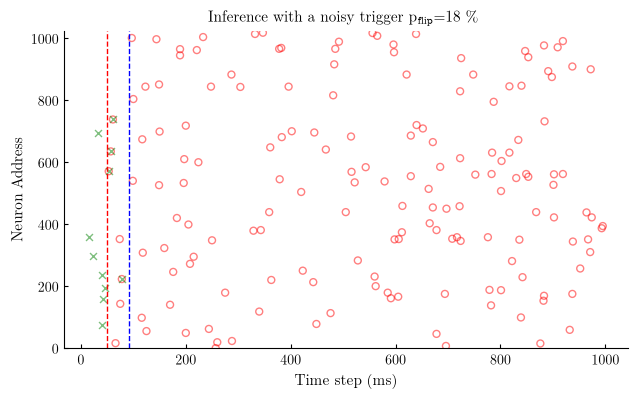

In [4]:
fig, ax = plt.subplots()
splt.raster(spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, c="blue", marker='+', alpha=.5)
splt.raster(target_full[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, facecolor='none', edgecolor='red',  marker='o', alpha=.5)
splt.raster(input_spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, c="green", marker='x', alpha=.5)
ax.vlines([opt.N_pretime], 0, opt.N_neuron_show, 'r', ls='--')
ax.vlines([opt.N_pretime+opt.num_delay], 0, opt.N_neuron_show, 'b', ls='--')
ax.set_xlabel("Time step (ms)")
ax.set_ylabel("Neuron Address")
ax.set_ylim(-1., opt.N_neuron_show + 1.)
ax.set_title(rf"Inference with a noisy trigger $p_{{\text{{flip}}}}$={hd.pattern_object.opt.p_flip*100:.0f} % ")
printfig(fig, 'p_flip_target', fig_width=opt.fig_width, fig_height=opt.fig_height, figpath=figpath)
spikes.shape, spikes[opt.i_pattern, :, :].sum().item(), target[opt.i_pattern, :, :].sum().item()

## Sweep: fixed weights, increasing trigger noise

`get_scores_noise`: for `N_scan` values of `p_flip` (linspace 0..1) and `N_cv`
independent realisations each, trigger the network and score the evoked window; the
trigger itself is corrupted (`target_ = pattern_object(seed=seed)`) while scoring still uses the
clean stored target - i.e. classic **pattern completion from a degraded cue**.
Results cached as `<datetag>_noise.npz` (arrays `p_flip`, `scores_np`, `scores_motif_np`) under the standard
`.lock` protocol.

In [5]:
# Fixed-weights sweep with N_cv repetitions per scan point: each repetition is an
# independent stochastic cue (the same seed drives the flips of pattern_object and the
# spontaneous pad of get_input_spikes - nb 20''s seed += 1 convention), scored against the
# clean frozen_target: classic pattern completion from a degraded cue. The cache is
# written after every scan point (with an n_done sentinel) so an interrupted run can
# resume from the file and a partial file is never mistaken for a complete one.

def get_scores_noise(N_scan=opt.N_scan, N_cv=opt.N_cv):
    p_flip = np.linspace(0, 1, N_scan, endpoint=True)
    scores_motif_np = np.zeros((N_scan, N_cv, hd.opt.N_pattern)) # F1 of each motif
    scores_np = np.zeros((N_scan, N_cv))
    target_evoked = hd.pattern_object.frozen_target[:, :, hd.opt.num_delay:]
    seed = hd.opt.seed # base seed, incremented per repetition (nb 20 convention)
    for i_scan in trange(N_scan):
        for i_cv in range(N_cv):
            with torch.no_grad():
                hd.pattern_object.opt.p_flip = p_flip[i_scan]
                target_ = hd.pattern_object(seed=seed)
                input_spikes = hd.get_input_spikes(target=target_, seed=seed)
                _, _, spikes = hd.forward_pass(input_spikes)
                spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]

                scores_np[i_scan, i_cv] = get_f1score(spikes_evoked, target_evoked)
                scores_motif_np[i_scan, i_cv] = get_f1score(spikes_evoked, target_evoked, dim=(1, 2)).cpu().numpy()
                seed += 1

        np.savez(npy_filename, p_flip=p_flip, scores_np=scores_np, scores_motif_np=scores_motif_np, n_done=i_scan + 1) # incremental save

    return p_flip, scores_np, scores_motif_np

npy_filename = data_cache / f"{hd.opt.datetag}_noise.npz"
lock_filename = npy_filename.with_suffix('.lock')
if RECOMPUTE:
    npy_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
    lock_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
try:
    data = np.load(npy_filename)
    p_flip = data['p_flip']
    scores_np = data['scores_np']
    if data['scores_np'].shape != (opt.N_scan, opt.N_cv) or ('n_done' not in data) or (data['n_done'] != opt.N_scan) or ('scores_motif_np' not in data):
        raise ValueError(f"Partial score file: {npy_filename}, re-evaluating.")
    scores_motif_np = data['scores_motif_np']
    lock_filename.unlink(missing_ok=True) # in case the lock file was not unlinked
    print(f"Score weights loaded from {npy_filename}") # Add a log message
except (FileNotFoundError, ValueError):
    with cache_lock(npy_filename) as acquired:
        if acquired:
            print(f"Score file not found: {npy_filename}, evaluating the score.")
            ##################
            p_flip, scores_np, scores_motif_np = get_scores_noise()
            ##################
            np.savez(npy_filename, p_flip=p_flip, scores_np=scores_np, scores_motif_np=scores_motif_np, n_done=opt.N_scan)
        else:
            print(f"Score file is locked: {lock_filename}, passing.")

Score weights loaded from ../cached_data/2026-09-07_noise.npz


In [6]:
# Reload the fixed-weights sweep (with named keys, tolerant of the n_done field).

data = np.load(npy_filename)
p_flip, scores_np, scores_motif_np = data['p_flip'], data['scores_np'], data['scores_motif_np']

## Expected F1 from theory

Two references are computed from the parameters; only the second one, the ignition of the replay,
is overlaid on the measured curves.

**Noisy copy (no pattern completion).** A balanced flip keeps a spike of the motif with
probability $q = 1 - p_\mathrm{flip}\,(1 - p_A)$, where $p_\mathrm{flip}$ is the bit-flip
probability and $p_A$ the firing probability of the motif, and turns an empty bin into a spike
with probability $p_\mathrm{flip}\,p_A$. The corrupted motif thus has an expected precision and
recall both equal to $q$:

$$F_1^\mathrm{copy} = 1 - p_\mathrm{flip}\,(1 - p_A),$$

a straight line from 1 down to chance level ($F_1 = p_A \approx 0$) at $p_\mathrm{flip} = 1$:
the score of a readout that would copy the corrupted motif as is.

**Ignition of the replay, a cascade.** With the minimum-norm (pseudo-inverse) readout, each spike
of a motif is supported by the $K$ spikes of that motif in the $D$ bins before it ($N$ neurons by
$D$ time bins), with equal weights: the membrane potential reaches 1 when all of them are present
and $k/K$ when only $k$ of them are, while a spurious spike falls on a near-zero weight (the motifs
are sparse). The spike is emitted if $k \geq \lceil \vartheta K \rceil$, with $\vartheta$ the firing
threshold. The replay is a cascade, a positive feedback loop: each emitted spike joins the support of the
next ones. Once the first evoked spike of a motif is emitted, the following ones find more and more
of their support, and the replay ignites as a whole and sustains itself; if it fails, their support
keeps shrinking and the replay dies out (see the dynamics below). The ignition probability $R$ is
thus that of the first evoked spike. A motif fires $\mu = p_A N$ spikes per bin, so this spike
comes $j$ bins after the trigger with probability $P(j) = e^{-\mu j}(1 - e^{-\mu})$, and its $K$
supporting spikes, in the last $D - j$ bins of the trigger window, follow a Poisson law of mean
$\lambda_j = \mu (D - j)$. Each supporting spike survives the flips with probability
$q_j = q$, hence

$$R = \frac{1}{R_0} \sum_{j=0}^{D-1} P(j) \sum_{K \geq 1} \frac{e^{-\lambda_j} \lambda_j^K}{K!} \sum_{k = \lceil \vartheta K \rceil}^{K} \binom{K}{k}\, q_j^k (1 - q_j)^{K - k},$$

normalised by its value $R_0 \approx 0.991$ for the intact trigger ($q_j = 1$: the first evoked
spike fires if it has at least one supporting spike), whose rare failures are already counted in
the measured recall.

An ignited motif is replayed with the noise-free precision $\pi_0$ and recall $r_0$, and a silent
one only adds false negatives. Per spike of the motifs, the true positives are $R\, r_0$, the false
negatives $1 - R\, r_0$ and the false positives $R\, r_0 (1/\pi_0 - 1)$, hence

$$F_1^\mathrm{ign} = \frac{2\, R\, r_0}{1 + R\, r_0 / \pi_0}.$$

**Two theories.** The formula above is the *first-spike theory* (orange line): it computes, in
closed form, only the first step of the cascade, averaged over the Poisson statistics of the
support. The *cascade theory* (green line, `get_f1_cascade`) simulates the whole replay instead:
1000 random motifs with the same statistics and the whole duration $T$, bin after bin, the emitted
spikes joining the support of the next ones, with the identity of the neurons kept in the trigger
window. The two theories agree when the first evoked spike decides the replay. Neither has a
fitted parameter: the threshold is the LIF threshold of the network, and only $\pi_0$ and $r_0$
are measured.

| symbol | name in the code | default value | role |
|---|---|---|---|
| $p_\mathrm{flip}$ | `p_flip` | swept in $[0, 1]$ (training: 0.01) | bit-flip probability of the trigger |
| $p_A$ | `p_A` | $1.6 \times 10^{-4}$ per 1 ms bin (0.16 Hz) | firing probability of the motif |
| $N$ | `N_neuron` | 1024 | number of neurons |
| $D$ | `num_delay` | 41 bins (41 ms) | width of the spiking-motif window and of the trigger |
| $\vartheta$ | `lif_threshold` | 0.75 | firing threshold, relative to the membrane potential reached on the motif |
| $\mu$ | `p_A * N_neuron` | 0.164 spike per bin | mean number of spikes of a motif per bin |
| $j$ | - | 0 to $D - 1$ bins (mean 5.6 ms) | delay of the first evoked spike after the trigger |
| $\lambda_j$ | `mu * (num_delay - j)` | 6.72 for $j = 0$ | mean number of spikes supporting the first evoked spike |
| $q$, $q_j$ | `get_trigger_presence` | $1 - p_\mathrm{flip}(1 - p_A)$ | probability that a spike of the motif survives the flips |
| $R$, $R_0$ | - | $R_0 \approx 0.991$ | ignition probability of a motif, and its value with an intact trigger |
| $\pi_0$, $r_0$ | `precision_0`, `recall_0` | measured at $p_\mathrm{flip} = 0$ | noise-free precision and recall of the replay |

The cell below measures $\pi_0$ and $r_0$ with the first repetition of the sweep protocol at
$p_\mathrm{flip} = 0$ (same seed), evaluates both theories, and reports their RMS error on the sweep.
In both score figures, the orange line is the first-spike theory $F_1^\mathrm{ign}$, the green line
the cascade theory, and the grey dashed lines mark $F_1 = 0$ and $F_1 = 1$.

In [7]:
# Noise-free precision and recall of the replay (first repetition of the sweep protocol at
# p_flip = 0, same seed): the only measured inputs of the ignition model.

with torch.no_grad():
    hd.pattern_object.opt.p_flip = 0.
    target_ = hd.pattern_object(seed=hd.opt.seed)
    _, _, spikes = hd.forward_pass(hd.get_input_spikes(target=target_, seed=hd.opt.seed))
    spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]
    target_evoked = hd.pattern_object.frozen_target[:, :, hd.opt.num_delay:]
    precision_0, recall_0, f1_score_0 = [score.item() for score in get_scores(spikes_evoked, target_evoked)]
print(f'p_flip = 0: precision = {precision_0:.3f}\t recall = {recall_0:.3f}\t f1_score = {f1_score_0:.3f}')

theory_dict = dict(p_A=opt.p_A, N_neuron=opt.N_neuron, num_delay=opt.num_delay,
                   lif_threshold=opt.lif_threshold, precision_0=precision_0, recall_0=recall_0)
p_flip_theory = np.linspace(0, 1, 201)
f1_ignition_theory = get_f1_ignition(p_flip_theory, **theory_dict)
f1_cascade_theory = get_f1_cascade(p_flip_theory, N_time=opt.N_time, **theory_dict) # whole replay, simulated
rmse_ignition = np.sqrt(np.mean((get_f1_ignition(p_flip, **theory_dict) - scores_np.mean(axis=1))**2))
rmse_cascade = np.sqrt(np.mean((get_f1_cascade(p_flip, N_time=opt.N_time, **theory_dict) - scores_np.mean(axis=1))**2))
print(f'lambda = p_A N D = {opt.p_A * opt.N_neuron * opt.num_delay:.2f} supporting spikes; RMS error on the sweep: '
      f'first-spike theory {rmse_ignition:.3f}, cascade theory {rmse_cascade:.3f}')

p_flip = 0: precision = 0.835	 recall = 0.825	 f1_score = 0.830


lambda = p_A N D = 6.72 supporting spikes; RMS error on the sweep: first-spike theory 0.042, cascade theory 0.042


Saving as ../figures/p_flip_score.pdf
Saving as ../figures/p_flip_score.png
Saving as ../figures/p_flip_score.svg


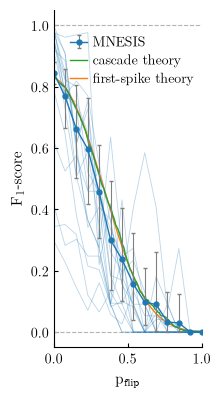

In [8]:
# $F_1$ as a function of the bit-flipping probability $p_\mathrm{flip}$: mean and 5%-95% quantiles of a beta fit over N_cv realisations, thin lines
# for each motif, against the two theories (orange: first spike; green: cascade); grey guides at 0 and 1.

if not lock_filename.exists():
    fig, ax = plt.subplots()
    ax.hlines([0, 1], p_flip[0], p_flip[-1], '0.7', ls='--', lw=0.8)
    ax.plot(p_flip_theory, f1_ignition_theory, color='tab:orange', label='first-spike theory')
    ax.plot(p_flip_theory, f1_cascade_theory, color='tab:green', label='cascade theory')
    # one thin line per motif (F1 of the motif, mean over the N_cv realisations), overlaid on the
    # mean: each motif switches from 0 to its intact value at its own threshold (all-or-nothing ignition)
    ax.plot(p_flip, scores_motif_np.mean(axis=1), color='tab:blue', alpha=.3, lw=.6)
    mean, yerr = get_beta_errorbar(scores_np)
    ax.errorbar(p_flip, mean, yerr=yerr, fmt='o',
                color='tab:blue', ecolor='0.5', elinewidth=0.8, capsize=1.5,
                markersize=3.5, linestyle='solid', linewidth=1.0, label='MNESIS')
    ax.set_xlabel(r"$p_\mathrm{flip}$")
    ax.set_ylabel(r"$F_1$-score")
    ax.set_xlim(p_flip[0], p_flip[-1])
    ax.set_ylim(-0.05, 1.05)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels[::-1], loc='upper right', bbox_to_anchor=(1., .95), # network first, below the F1 = 1 line
              handlelength=1.2, handletextpad=0.4, borderaxespad=0.2, labelspacing=0.3)

    printfig(fig, 'p_flip_score', fig_width=opt.fig_width/3, fig_height=opt.fig_height, figpath=figpath)


## Dynamics of the replay: a cascade

The ignition model assumes that the replay of each motif either ignites as a whole and sustains
itself, or dies out. The recall of each motif in successive windows of $D = 41$ ms of the evoked
window (`HD_SNN.get_recall_time`) shows it directly, for a few noise levels (thin lines: single
motifs; thick lines: mean over the $M = 16$ motifs): each motif settles on the recall of the
intact trigger or on zero, a bistable dynamics, and the noise only changes the number of
motifs that ignite. In the open-loop control (dashed black, `forward_pass(..., feedback=False)`,
with the intact trigger), the output spikes are not fed back: each neuron only sees the trigger,
which drives the first $D$ ms of the evoked window, after which the activity vanishes. The replay
is thus sustained by the recurrent positive feedback, not by the trigger. A few motifs stop late
in the evoked window even with the intact trigger: these failures do not depend on the trigger and
are part of the measured recall $r_0$.

Saving as ../figures/p_flip_cascade.pdf
Saving as ../figures/p_flip_cascade.png
Saving as ../figures/p_flip_cascade.svg


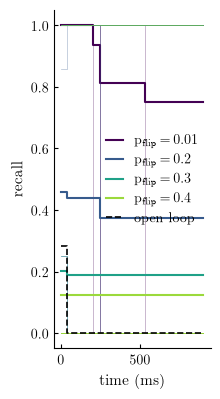

In [9]:
# Recall of each motif per window of num_delay bins for a few noise levels (closed loop), and for
# the open-loop control (output spikes not fed back) with the intact trigger. opt is shared with
# the pattern generator, whose p_flip the sweeps overwrite: Params.p_flip is the training default.

p_flip_levels = [Params.p_flip, 0.2, 0.3, 0.4]
recall_time = []
for p_flip_level in p_flip_levels:
    hd.pattern_object.opt.p_flip = p_flip_level
    cue = hd.pattern_object(seed=opt.seed)
    recall_time.append(hd.get_recall_time(hd.get_input_spikes(target=cue, seed=opt.seed)))
hd.pattern_object.opt.p_flip = Params.p_flip
cue = hd.pattern_object(seed=opt.seed)
recall_open = hd.get_recall_time(hd.get_input_spikes(target=cue, seed=opt.seed), feedback=False)
labels = [rf'$p_\mathrm{{flip}} = {p:g}$' for p in p_flip_levels]

fig, ax = plt.subplots()
plot_recall_time(ax, recall_time, labels, recall_open=recall_open, bin_width=opt.num_delay)
ax.legend(loc='center right', handlelength=1.2, labelspacing=0.3)
printfig(fig, 'p_flip_cascade', fig_width=opt.fig_width/3, fig_height=opt.fig_height, figpath=figpath)

## Control: fine-tune the network for each noise level to improve WM

If graceful degradation is caused by training at `p_flip=0.01` only, training a *matched*
model per noise level should push the whole F1 curve up. Hypothesis under test:
robustness to corrupted cues is learnable (data augmentation at the right level).
Each scan point fine-tunes the vanilla readout (`load` then `learn_model`, `verbose=False`)
on a `Params` instantiated with that `p_flip`, then evaluates it N_cv times with the same protocol as
the fixed-weights sweep. Cached as `<datetag>_noise_retrain.npz`.

In [10]:
# Control condition: one model per p_flip, fine-tuned from the vanilla checkpoint by
# learn_model at that noise level (learning hoisted out of the CV loop, with local variables so the global hd/opt/model_filename are left untouched),
# then evaluated N_cv times under the same seeded protocol and the same frozen-target
# reference as the fixed-weights sweep. Incremental save with an n_done sentinel.

def get_scores_retrain_noise(N_scan=opt.N_scan, N_cv=opt.N_cv):
    p_flip = np.linspace(0., 1., N_scan, endpoint=True)
    scores_np = np.zeros((N_scan, N_cv))
    i_start = 0
    if npy_filename.exists(): # resume: each scan point re-seeds itself (Params.__post_init__),
        data = np.load(npy_filename) # so cached rows are valid; continue after n_done
        if data['scores_retrain_np'].shape == (N_scan, N_cv):
            scores_np = data['scores_retrain_np']
            i_start = int(data['n_done']) if 'n_done' in data else N_scan
    # base seed of the first scan point left to compute, incremented per repetition (nb 20 convention)
    seed = opt.seed + opt.N_cv * i_start
    for i_scan in trange(i_start, N_scan):
        ##################
        opt_local = Params(p_flip=p_flip[i_scan])
        model_filename_local = data_cache / f"{opt_local.datetag}_vanilla.pth"
        hd_local = load(opt_local, model_filename_local)
        # REDUNDANT: hd_local.pattern_object.opt.p_flip = p_flip[i_scan]
        hd_local.learn_model(verbose=False)
        ##################
        target_evoked = hd_local.pattern_object.frozen_target[:, :, hd_local.opt.num_delay:]
        for i_cv in range(N_cv):
            with torch.no_grad():
                target_ = hd_local.pattern_object(seed=seed)
                input_spikes = hd_local.get_input_spikes(target=target_, seed=seed)
                _, _, spikes = hd_local.forward_pass(input_spikes)
                spikes_evoked = spikes[:, :, (hd_local.opt.N_pretime+hd_local.opt.num_delay):(hd_local.opt.N_time+hd_local.opt.N_pretime)]

                scores_np[i_scan, i_cv] = get_f1score(spikes_evoked, target_evoked)
                seed += 1

        np.savez(npy_filename, p_flip_retrain=p_flip, scores_retrain_np=scores_np, n_done=i_scan + 1) # incremental save

    return p_flip, scores_np

npy_filename = data_cache / f"{hd.opt.datetag}_noise_retrain.npz"
lock_filename = npy_filename.with_suffix('.lock')
if RECOMPUTE:
    npy_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
    lock_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
try:
    data = np.load(npy_filename)
    p_flip_retrain = data['p_flip_retrain']
    scores_retrain_np = data['scores_retrain_np']
    if data['scores_retrain_np'].shape != (opt.N_scan, opt.N_cv) or ('n_done' not in data) or (int(data['n_done']) != opt.N_scan):
        raise ValueError(f"Partial score file: {npy_filename}, resuming.")
    lock_filename.unlink(missing_ok=True) # in case the lock file was not unlinked
    print(f"Score weights loaded from {npy_filename}") # Add a log message
except (FileNotFoundError, ValueError):
    with cache_lock(npy_filename) as acquired:
        if acquired:
            print(f"Score file not found: {npy_filename}, evaluating the score.")
             ##################
            p_flip_retrain, scores_retrain_np = get_scores_retrain_noise()
             ##################
            np.savez(npy_filename, p_flip_retrain=p_flip_retrain, scores_retrain_np=scores_retrain_np, n_done=opt.N_scan)
        else:
            print(f"Score file is locked: {lock_filename}, passing.")

Score file is locked: ../cached_data/2026-09-07_noise_retrain.lock, passing.


In [11]:
# # Reload the retrain control (robust to the scan cell having taken the locked branch).

# try:
#     data = np.load(npy_filename)
#     p_flip_retrain, scores_retrain_np = data['p_flip_retrain'], data['scores_retrain_np']
#     print(f"Retrain scores loaded from {npy_filename}")
# except FileNotFoundError:
#     p_flip_retrain, scores_retrain_np = None, None
#     print(f"Retrain score file not available yet: {npy_filename} (locked or not computed).")

In [12]:
# # Overlay fixed-weights (blue) vs fine-tuned (red) $F_1$ vs $p_\mathrm{flip}$, and the ignition model (dashed).

# if not lock_filename.exists():
#     fig, ax = plt.subplots()
#     ax.hlines([0, 1], p_flip[0], p_flip[-1], 'orange', ls='--', lw=0.8)
#     ax.plot(p_flip_theory, f1_ignition_theory, color='k', ls='--')
#     ax.plot(p_flip_theory, f1_cascade_theory, color='k', ls=':')
#     mean, yerr = get_beta_errorbar(scores_np)
#     ax.errorbar(p_flip, mean, yerr=yerr, fmt='o',
#                 color='tab:blue', ecolor='0.5', elinewidth=0.8, capsize=1.5,
#                 markersize=3.5, linestyle='solid', linewidth=1.0, label='fixed weights')
#     if scores_retrain_np is not None:
#         mean_retrain, yerr_retrain = get_beta_errorbar(scores_retrain_np)
#         ax.errorbar(p_flip_retrain, mean_retrain, yerr=yerr_retrain, fmt='o',
#                     color='tab:red', ecolor='0.5', elinewidth=0.8, capsize=1.5,
#                     markersize=3.5, linestyle='solid', linewidth=1.0, label='fine-tuned')
#     ax.set_xlabel(r"$p_\mathrm{flip}$")
#     ax.set_ylabel(r"$F_1$-score")
#     ax.set_xlim(p_flip[0], p_flip[-1])
#     ax.set_ylim(-0.05, 1.05)
#     ax.legend(loc='best')

#     printfig(fig, 'p_flip_retrain_score', fig_width=opt.fig_width/3, fig_height=opt.fig_height, figpath=figpath)
